# E04 · Training with contrast and brightness augmentation

Same as `E02_hist_split` (EfficientNet-B0, 12 bands, `hist_split`-corrected training images,
same hyperparameters). **One change:** during training, every image gets random **contrast** and
**brightness** changes.

**Why.** `04_haze_correction` showed that after `hist_split`, brightness and colour of training and test
images match, but test images have **more contrast within each image** (median ratio test/train:
1.10–1.35 in most bands, about 1.9 in B01/B09). Haze lowers contrast by a different amount in every
image, so one global correction can't remove it. Instead, the model sees many contrast levels during
training and should learn to ignore them.

| Setting (`PhotometricAugment`) | Value | Meaning |
|---|---|---|
| `contrast` | 0.9 – 1.5 | per image: scale deviations from the image's mean |
| `band_contrast` | 0.9 – 1.15 | extra per-band factor on top |
| `brightness` | 0.93 – 1.07 | per band: multiply all values |
| `p` | 0.8 | share of training images that get the change |

On average this raises contrast by about 17% (up to about 1.7×), covering the measured test values.

| | E02 (hist_split) | This run |
|---|---|---|
| Contrast/brightness augmentation | no | **yes** |
| Kaggle public | 64.06% | see below |

Section 7 also applies **AdaBN (balanced)** from `E03_adabn` to this model, as a second run folder,
so it can be compared with the best result at that time (`E03_adabn`, 65.28%).

**Train or load.** `LOAD_RUN` points to this experiment's saved run: the notebook loads its
weights and recomputes every result and the submission file in about a minute. Set
`LOAD_RUN = None` to train a new model (about 20 minutes on an M4 GPU).

## 1 · Setup

In [1]:
import json
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS
from src.experiment import (adabn_balanced, class_mix, find_run, kaggle_monitor,
                            load_experiment_data, plot_class_mix, plot_confusion_matrix,
                            plot_training_curves, view_agreement)
from src.training import PhotometricAugment
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import (Normalizer, TrainConfig, fit, load_run, new_run_dir, predict_proba,
                          predict_views, save_run, write_submission)
from src.utils import count_parameters, describe_device, get_device, seed_everything

apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E04_contrast_aug"
RUN_NAME = "contrast_aug_hist_split_effb0"
DESCRIPTION = "hist_split + contrast/brightness augmentation"
LOAD_RUN = "runs/2026-10-12_1040_contrast_aug_hist_split_effb0"   # None = train a new model
CORRECTIONS = ['hist_split']   # applied to EuroSAT images, in this order
MODEL = "efficientnet_b0"
BANDS = list(TEST_BANDS)              # all 12 bands
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))

Device: Apple GPU (MPS)


## 2 · Data

EuroSAT images (train / val / internal test, split from `03_split`) are corrected with `CORRECTIONS`;
Kaggle images are used as they are. The normalisation statistics come from the training split only.

In [2]:
data = load_experiment_data(BANDS, CORRECTIONS, device)
normalizer = Normalizer.fit(data.X_tr)
print(data.summary())

train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232


### What the augmentation does

One validation image per class (already corrected), original and three random contrast/brightness
versions. Same display scaling everywhere.

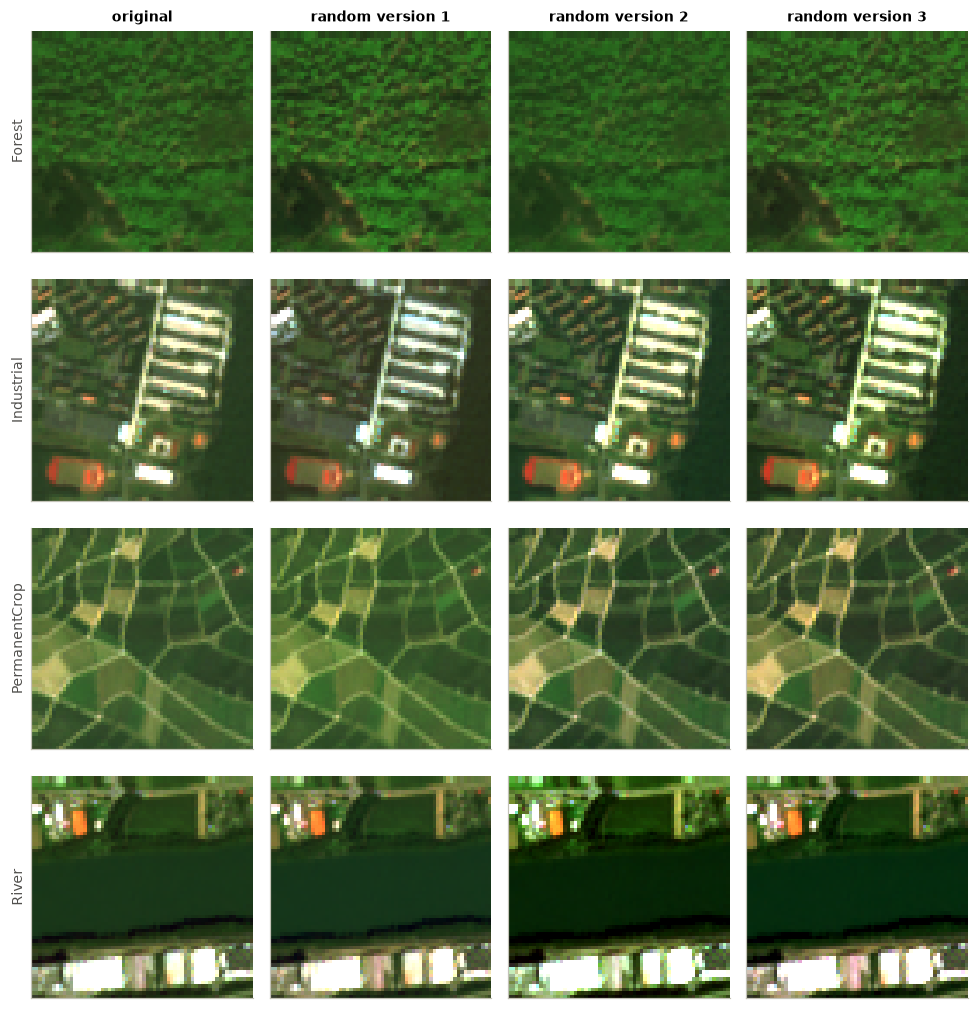

In [3]:
torch.manual_seed(0)
show_classes = ["Forest", "Industrial", "PermanentCrop", "River"]
rgb_idx = [BANDS.index(b) for b in ["B04", "B03", "B02"]]
to_rgb = lambda img, vmax=1500: np.clip(img[rgb_idx] / vmax, 0, 1).transpose(1, 2, 0)
always = PhotometricAugment(**{**cfg.photometric, "p": 1.0})

fig, axes = plt.subplots(len(show_classes), 4, figsize=(9, 9.4))
for r, cls in enumerate(show_classes):
    i = np.flatnonzero(data.y_va == CLASSES.index(cls))[0]
    img = torch.from_numpy(data.X_va[i:i + 1].astype(np.float32))
    for c, v in enumerate([img] + [always(img) for _ in range(3)]):
        axes[r, c].imshow(to_rgb(v[0].numpy()))
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([]); axes[r, c].grid(False)
        if r == 0:
            axes[r, c].set_title("original" if c == 0 else f"random version {c}", fontsize=9)
    axes[r, 0].set_ylabel(cls, fontsize=9)
plt.tight_layout()
plt.show()

## 3 · Model and training

After every epoch the model also predicts the unlabelled Kaggle images, to watch the domain shift
without spending submissions (mean confidence, predicted class shares).

In [4]:
if LOAD_RUN:
    model, normalizer, _ = load_run(PROJECT_ROOT / LOAD_RUN, device)
    history = pd.read_csv(PROJECT_ROOT / LOAD_RUN / "history.csv")
    print(f"Loaded weights and training history ({len(history)} epochs) from {LOAD_RUN}: no training")
else:
    model = build_model(MODEL, bands=BANDS, pretrained=True).to(device)
    history, best_state = fit(model, data.tr_images, data.tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer))

n_params = count_parameters(model)
assert n_params <= MEDIUM_TRACK_LIMIT, "too many parameters for the medium track"
print(f"{MODEL}: {n_params:,} parameters (medium track limit {MEDIUM_TRACK_LIMIT:,})")

Loaded weights and training history (20 epochs) from runs/2026-10-12_1040_contrast_aug_hist_split_effb0: no training
efficientnet_b0: 4,022,950 parameters (medium track limit 10,000,000)


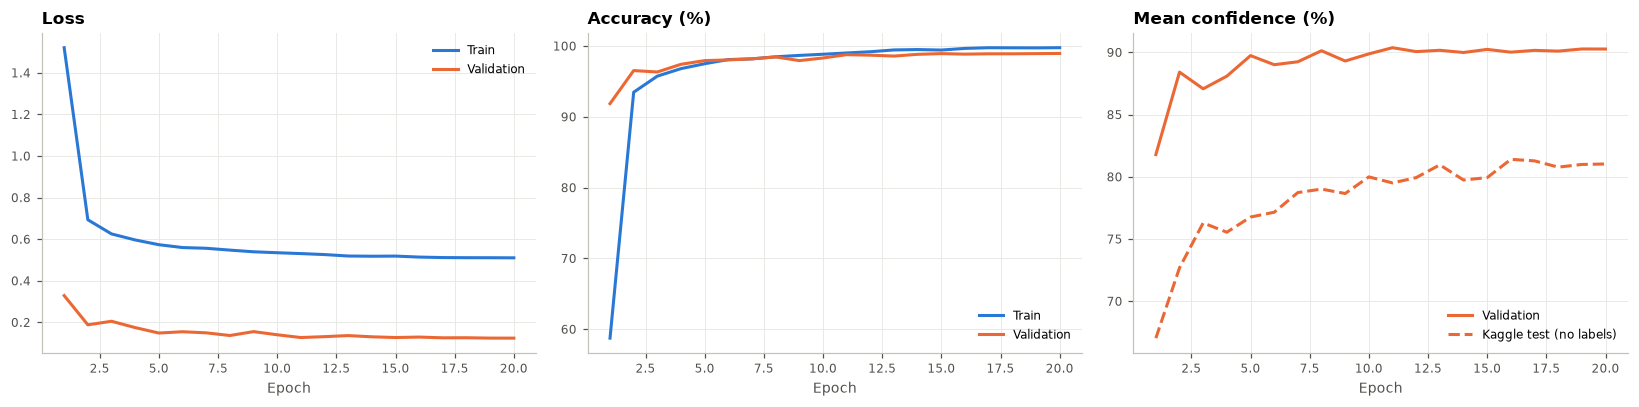

In [5]:
plot_training_curves(history)

## 4 · Internal test set

Measured once, on the best epoch: how well the model learned EuroSAT itself. It says nothing about
the Level-2A Kaggle images.

In [6]:
te_pred = predict_proba(model, data.te_images, normalizer).argmax(1)
val_acc = float(history["val_acc"].max())
test_acc = float((te_pred == data.y_te).mean())
print(f"Validation accuracy (best epoch): {val_acc:.2%}")
print(f"Internal test accuracy:           {test_acc:.2%}\n")
print(classification_report(data.y_te, te_pred, target_names=CLASSES, digits=3))

Validation accuracy (best epoch): 98.94%
Internal test accuracy:           98.77%

                      precision    recall  f1-score   support

          AnnualCrop      0.974     0.982     0.978       450
              Forest      0.996     0.998     0.997       450
HerbaceousVegetation      0.980     0.987     0.983       450
             Highway      0.989     0.981     0.985       375
          Industrial      0.992     0.997     0.995       375
             Pasture      0.977     0.970     0.973       300
       PermanentCrop      0.981     0.965     0.973       375
         Residential      0.998     0.996     0.997       450
               River      0.987     0.992     0.989       375
             SeaLake      1.000     1.000     1.000       450

            accuracy                          0.988      4050
           macro avg      0.987     0.987     0.987      4050
        weighted avg      0.988     0.988     0.988      4050



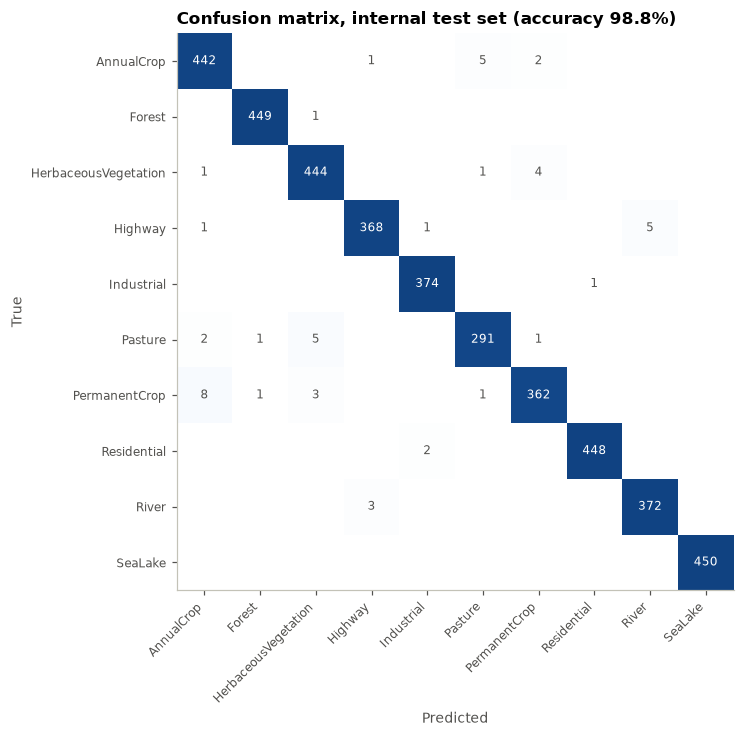

In [7]:
plot_confusion_matrix(data.y_te, te_pred, f"Confusion matrix, internal test set (accuracy {test_acc:.1%})")

## 5 · Kaggle predictions

Kaggle images as they are, normalised with the training statistics; test-time augmentation averages
the 8 rotations/flips of each image.

Mean confidence on Kaggle images: 78.4%


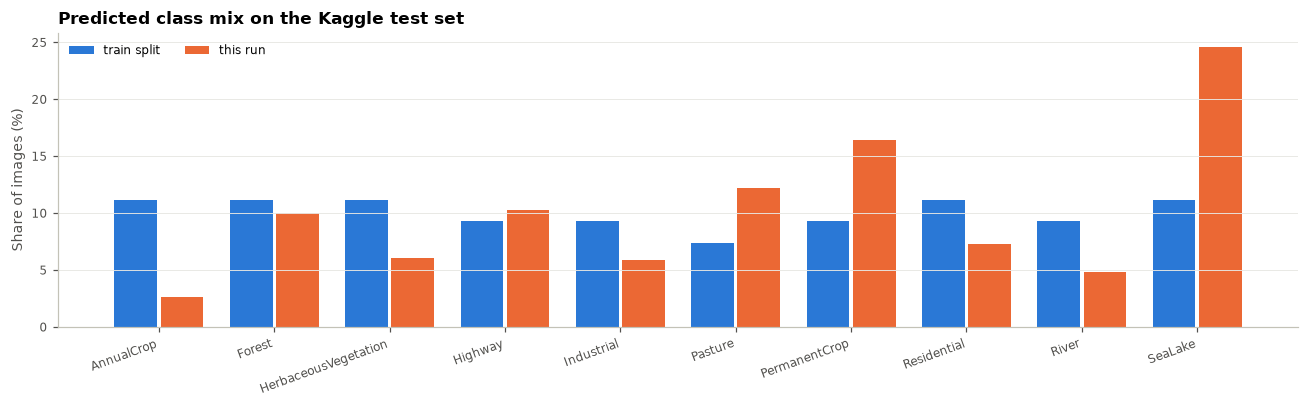

,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
train split,11.1,11.1,11.1,9.3,9.3,7.4,9.3,11.1,9.3,11.1
this run,2.6,10.0,6.0,10.2,5.9,12.2,16.4,7.3,4.8,24.6


In [8]:
kg_prob = predict_proba(model, data.kg_images, normalizer, tta=True)
kg_conf = float(kg_prob.max(1).mean())
mix = pd.DataFrame({"train split": class_mix(np.eye(10)[data.y_tr]), "this run": class_mix(kg_prob)})
print(f"Mean confidence on Kaggle images: {kg_conf:.1%}")
plot_class_mix(mix)
mix.round(1).T

## 6 · Save the run

With `LOAD_RUN` nothing is retrained or overwritten except `submission.csv`, recomputed from the saved weights.

In [9]:
if LOAD_RUN:
    run_dir = PROJECT_ROOT / LOAD_RUN
else:
    run_dir = new_run_dir(RUN_NAME)
    config = {
        "run_name": run_dir.name, "description": DESCRIPTION, "notebook": NOTEBOOK, "model": MODEL,
        "bands": BANDS, "seed": SEED, "n_params": n_params, "device": describe_device(device),
        "normalizer": asdict(normalizer), "corrections": CORRECTIONS, "train": asdict(cfg),
        "split": "split_seed42",
    }
    metrics = {
        "val_acc": val_acc, "internal_test_acc": test_acc,
        "best_epoch": int(history.loc[history["val_acc"].idxmax(), "epoch"]),
        "kaggle_mean_confidence": kg_conf,
        "kaggle_predicted_mix_pct": mix["this run"].round(2).to_dict(),
        "kaggle_public_score": None,  # fill in after submitting
    }
    save_run(run_dir, best_state, config, history, metrics)

write_submission(kg_prob, data.test_ids, run_dir / "submission.csv")
print("Run folder:", run_dir.relative_to(PROJECT_ROOT))
for f in sorted(run_dir.iterdir()):
    print(f"  {f.name:20} {f.stat().st_size / 1e6:6.2f} MB")

Run folder: runs/2026-10-12_1040_contrast_aug_hist_split_effb0
  config.json            0.00 MB
  history.csv            0.01 MB
  metrics.json           0.00 MB
  model.pt              16.35 MB
  submission.csv         0.06 MB


## 7 · With AdaBN (balanced)

As in `E03_adabn`: re-measure the BatchNorm statistics on Kaggle images, using all land images plus
enough water images to match the training water share. Saved as a second run folder. With `LOAD_RUN`,
the saved adapted weights are loaded instead of re-measuring.

In [10]:
if LOAD_RUN:
    ada_dir = find_run(f"adabn_balanced_{RUN_NAME}")
    ada_model, ada_norm, _ = load_run(ada_dir, device)
    print("Loaded adapted weights from", ada_dir.relative_to(PROJECT_ROOT))
else:
    ada_model, ada_norm, _ = load_run(run_dir, device)
    ada_model, bn_idx = adabn_balanced(ada_model, ada_norm, data, SEED)

views_plain = predict_views(model, data.kg_images, normalizer)
views_ada = predict_views(ada_model, data.kg_images, ada_norm)
prob_ada = views_ada.mean(0)

if not LOAD_RUN:
    ada_dir = new_run_dir(f"adabn_balanced_{RUN_NAME}")
    torch.save({k: v.detach().cpu() for k, v in ada_model.state_dict().items()}, ada_dir / "model.pt")
    ada_config = {**json.loads((run_dir / "config.json").read_text()), "run_name": ada_dir.name,
                  "description": DESCRIPTION + " + AdaBN balanced", "base_run": str(run_dir.relative_to(PROJECT_ROOT)),
                  "method": "adabn_balanced", "n_bn_images": int(len(bn_idx))}
    ada_metrics = {"kaggle_mean_confidence": float(prob_ada.max(1).mean()),
                   "kaggle_view_agreement": view_agreement(views_ada),
                   "kaggle_predicted_mix_pct": class_mix(prob_ada).round(2).to_dict(),
                   "kaggle_public_score": None}
    (ada_dir / "config.json").write_text(json.dumps(ada_config, indent=2))
    (ada_dir / "metrics.json").write_text(json.dumps(ada_metrics, indent=2))
write_submission(prob_ada, data.test_ids, ada_dir / "submission.csv")

sealake = CLASSES.index("SeaLake")
pd.DataFrame({
    "confidence (%)": [views_plain.mean(0).max(1).mean() * 100, prob_ada.max(1).mean() * 100],
    "view agreement (%)": [view_agreement(views_plain) * 100, view_agreement(views_ada) * 100],
    "SeaLake (%)": [(views_plain.mean(0).argmax(1) == sealake).mean() * 100, (prob_ada.argmax(1) == sealake).mean() * 100],
}, index=["this run", "this run + AdaBN balanced"]).round(1)

Loaded adapted weights from runs/2026-10-12_1040_adabn_balanced_contrast_aug_hist_split_effb0


,confidence (%),view agreement (%),SeaLake (%)
this run,78.400002,72.8,24.6
this run + AdaBN balanced,73.599998,72.5,24.6


## 8 · Conclusion

Label-free comparison on the Kaggle images (before submitting):

| Model | Confidence | View agreement | PermanentCrop / AnnualCrop | Kaggle public |
|---|---|---|---|---|
| E02 hist_split | 75.1% | 73.0% | 18.7% / 2.4% | 64.06% |
| E03 + AdaBN balanced | 71.8% | 70.2% | 9.4% / 8.8% | 65.28% |
| **E04 contrast aug** | **78.4%** | 72.8% | 16.4% / 2.6% | 64.39% |
| **E04 contrast aug + AdaBN balanced** | 73.6% | 72.5% | 9.0% / 8.7% | **68.18%** |

- **EuroSAT accuracy is unchanged** (validation 98.94%, internal test 98.77%): the augmentation doesn't cost anything on the training domain.
- **The model is more confident on Kaggle images** (+3.3 points vs `E02`) and its predictions are a bit more stable during training (class-mix change per epoch 6.5 vs 8.0 points), so contrast differences unsettle it less.
- **The crop confusion remains without AdaBN** (PermanentCrop 16.4%, AnnualCrop 2.6%). With AdaBN it disappears again, as in `E03_adabn`.
- **Contrast aug + AdaBN** is slightly better than `E03_adabn` on both label-free measures (confidence +1.8, view agreement +2.3 points) and agrees with it on 87.5% of the images. Expect a small improvement over 65.28%, if any; only Kaggle can tell.

**Kaggle result:** the augmentation alone adds only +0.3 points (64.39% vs 64.06%), but together with AdaBN
it adds +2.9 points over `E03_adabn` (68.18% vs 65.28%). The two methods work together: AdaBN shifts the
internal statistics to the test images, and the contrast-trained model copes much better with that shift.